<!-- repo-header -->
# The original 4 x 32 hardware build  *(superseded)*

The first end-to-end Q-MERGE Stage-1 circuit: M = 4 segments of N = 32, with 10 SSO
layers per segment. Superseded by the 4 x 1024 build in
`chapter5_qmerge/03_hardware_circuit_build.ipynb`, which is what the thesis reports.

Kept because its artefacts (`mre_qc.qpy`, `shadow_branch_hw.pkl`,
`shadow_vs_fidelity_rows_orth.npz`, all in `chapter5_qmerge/`) are still read by
cell 9 of the figures notebook, which produces `hardware_results_final.pdf`.

One cell is commented out and begins `#DO NOT RUN AS WILL OVERWRITE CIRCUIT` -- that
is deliberate and has been left exactly as it was.


# Multi-register CSWAP compression -- 4x32 R75, SSO staircase prep (Stage 1)

Full-statevector build & verification of **Stage 1** of *Parallelism of State
Preparation Algorithms via Multi-Register Encoding*: prepare the M rows on separate
registers with the **SSO staircase circuits** (10 chi=2 layers, ~1e-8 infidelity), then
compress onto a storage+index register with SELECT-SWAP gates to recover the weighted
stack

$$|\psi_w\rangle=\tfrac{1}{\sqrt N}\sum_i w_i\,|\psi_i\rangle_S|i\rangle_I,
\qquad w_i=\prod_{k\ne i}(\psi_k)_{u_k}.$$

Modules used:
* **`sso_prep.py`** -- the SSO/MPS disentangler + analytic MPS->circuit stack (extracted
  verbatim from *Small R75 for hardware run.ipynb*, cell 0).
* **`sso_rowprep.py`** -- wraps it into Qiskit staircase circuits whose statevector equals
  the row (little-endian), ready to drop into the compression circuit.
* **`mre_prep.py`** -- the compression machinery + analytic oracle for the smoke tests.

The row prep is added as `qc.unitary` staircase gates (not a `StatePreparation` box), so
the full circuit shows every 2-qubit gate of the state preparation. The end-to-end
reconstruction fidelity equals $\prod_i F_i$ (Eq. 5) -- a direct cross-check of the SSO
row fidelities.

In [1]:
# NOTE: %autoreload is deliberately NOT used here -- on this machine/IPython version
# it triggers a noisy (non-fatal) UnicodeDecodeError from the `deduperreload` extension
# scanning stdlib source files under Windows' cp1252 default encoding, and forcibly
# redirecting stderr to suppress it destabilises the live ipykernel (confirmed: breaks
# its ZMQ heartbeat). Instead: after editing mre_prep.py / sso_rowprep.py, just re-run
# THIS cell (it explicitly importlib.reload()s both) before re-running downstream cells.
import importlib, io, contextlib, warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import mre_prep as mre
importlib.reload(mre)
# sso_rowprep imports the SSO stack, which prints self-checks on import -- silence them
with contextlib.redirect_stdout(io.StringIO()):
    import sso_rowprep as srp
    importlib.reload(srp)
np.set_printoptions(precision=4, suppress=True)

def show(qc, **kw):
    """Draw with matplotlib; fall back to text if pylatexenc/mpl is unavailable."""
    try:
        return qc.draw('mpl', **kw)
    except Exception as e:
        print(f"(mpl draw unavailable -> text): {e}")
        return qc.draw('text', fold=-1)

## 1. Load the 4x32 R75 data

`resize(df, (rowlen, n_rows))`, row `i` is `Y.T[i]`. Here `n_rows = M = 4`,
`rowlen = N = 32` -> `n = 5` qubits/chunk, `m = 2` index qubits. Displayed as the
rows-across `|amplitude|` heatmap (same style as the analysis notebook).

data shape (32, 4) -> 4 chunks of length 32


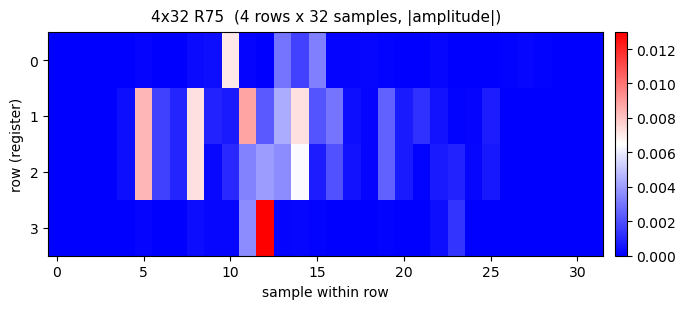

In [2]:
import pandas as pd
from skimage.transform import resize

M, N = 4, 32
df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
Y = resize(df.to_numpy(), (N, M), anti_aliasing=True)         # (rowlen=32, n_rows=4)
chunks = [Y.T[i].astype(complex) / np.linalg.norm(Y.T[i]) for i in range(M)]
print("data shape", Y.shape, "->", M, "chunks of length", N)

img = np.abs(Y.T)                                             # (4 rows, 32 samples)
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(img, aspect='auto', cmap='bwr', interpolation='nearest',
               vmin=img.min(), vmax=img.max())
ax.set_title('4x32 R75  (4 rows x 32 samples, |amplitude|)', fontsize=11, pad=8)
ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')
ax.set_yticks(range(M))
plt.colorbar(im, ax=ax, fraction=0.05, pad=0.02); plt.tight_layout(); plt.show()

## 2. SSO staircase row preparation (10 chi=2 layers)

Each row is disentangled into 10 staircase layers of 2-qubit SU(4) gates plus the
analytic prep of the chi=2 residual. `build_prep_circuits` returns one Qiskit circuit per
row (statevector == row to the SSO fidelity) and the achieved per-row fidelities.

In [ ]:
#DO NOT RUN AS WILL OVERWRITE CIRCUITS
#prep_circuits, fids = srp.build_prep_circuits(chunks, chi=2, num_layers=10, n_iter=200)
#prodF = float(np.prod(fids))
#print(f"\nprod_i F_i = {prodF:.10f}   (combined infidelity {1-prodF:.2e})")
#print(f"one row prep: {prep_circuits[0].num_qubits} qubits, "
      #f"{prep_circuits[0].size()} staircase gates")

  row 0: SSO final fid = 0.9999999998   (infidelity 2.00e-10)


  row 1: SSO final fid = 0.9999999999   (infidelity 1.43e-10)


  row 2: SSO final fid = 0.9999999990   (infidelity 1.01e-09)


  row 3: SSO final fid = 1.0000000000   (infidelity -4.44e-16)

prod_i F_i = 0.9999999986   (combined infidelity 1.35e-09)
one row prep: 5 qubits, 55 staircase gates


### 2a. The staircase for one row

Row 0's prep circuit: the analytic residual prep (`Vp`) followed by the 10 reverse
staircase layers (`V`). This is the structure that appears on every `A_i` in the full
circuit below.

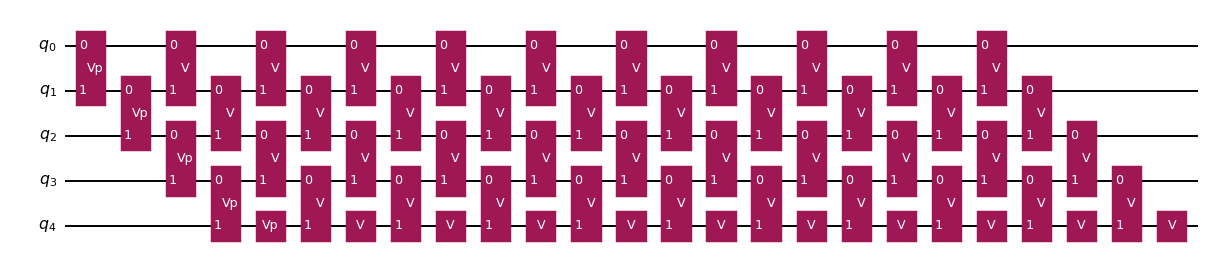

In [4]:
show(prep_circuits[0], fold=-1, scale=0.7)

### 2b. Per-row prep check

`Statevector(prep_i)` vs the target row should equal the SSO fidelity `F_i`.

In [5]:
from qiskit.quantum_info import Statevector
for i in range(M):
    f = mre.fidelity(np.asarray(Statevector(prep_circuits[i])), chunks[i])
    print(f"row {i}: fidelity(prep|0>, row) = {f:.10f}   (reported F_i = {fids[i]:.10f})")

row 0: fidelity(prep|0>, row) = 0.9999999997   (reported F_i = 0.9999999998)
row 1: fidelity(prep|0>, row) = 0.9999999997   (reported F_i = 0.9999999999)
row 2: fidelity(prep|0>, row) = 0.9999999990   (reported F_i = 0.9999999990)
row 3: fidelity(prep|0>, row) = 0.9999999999   (reported F_i = 1.0000000000)


## 3. Build the compression circuit (SSO prep composed in)

Registers **S, I, A_0..A_3, anc** (low->high). Each `A_i` gets the SSO staircase (composed,
so every gate is visible), then `S`,`I` go into superposition, then the SELECT-SWAPs use
the paper's **Fig. 2 decomposition** (2 C^mNOT + n CSWAP + one zeroed ancilla; the C^mNOT
is a Toffoli at m=2).

`barrier=True` inserts a visual separator between prep and compression so each C^mSWAP
block renders as a unit (otherwise the first C^mNOT slides left into the prep region). It
is a no-op for simulation; drop it (`barrier=False`) before hardware compilation.

qubits = 28  (S=5, I=2, 4xA=20, anc=1)
depth  = 53   gates = 255


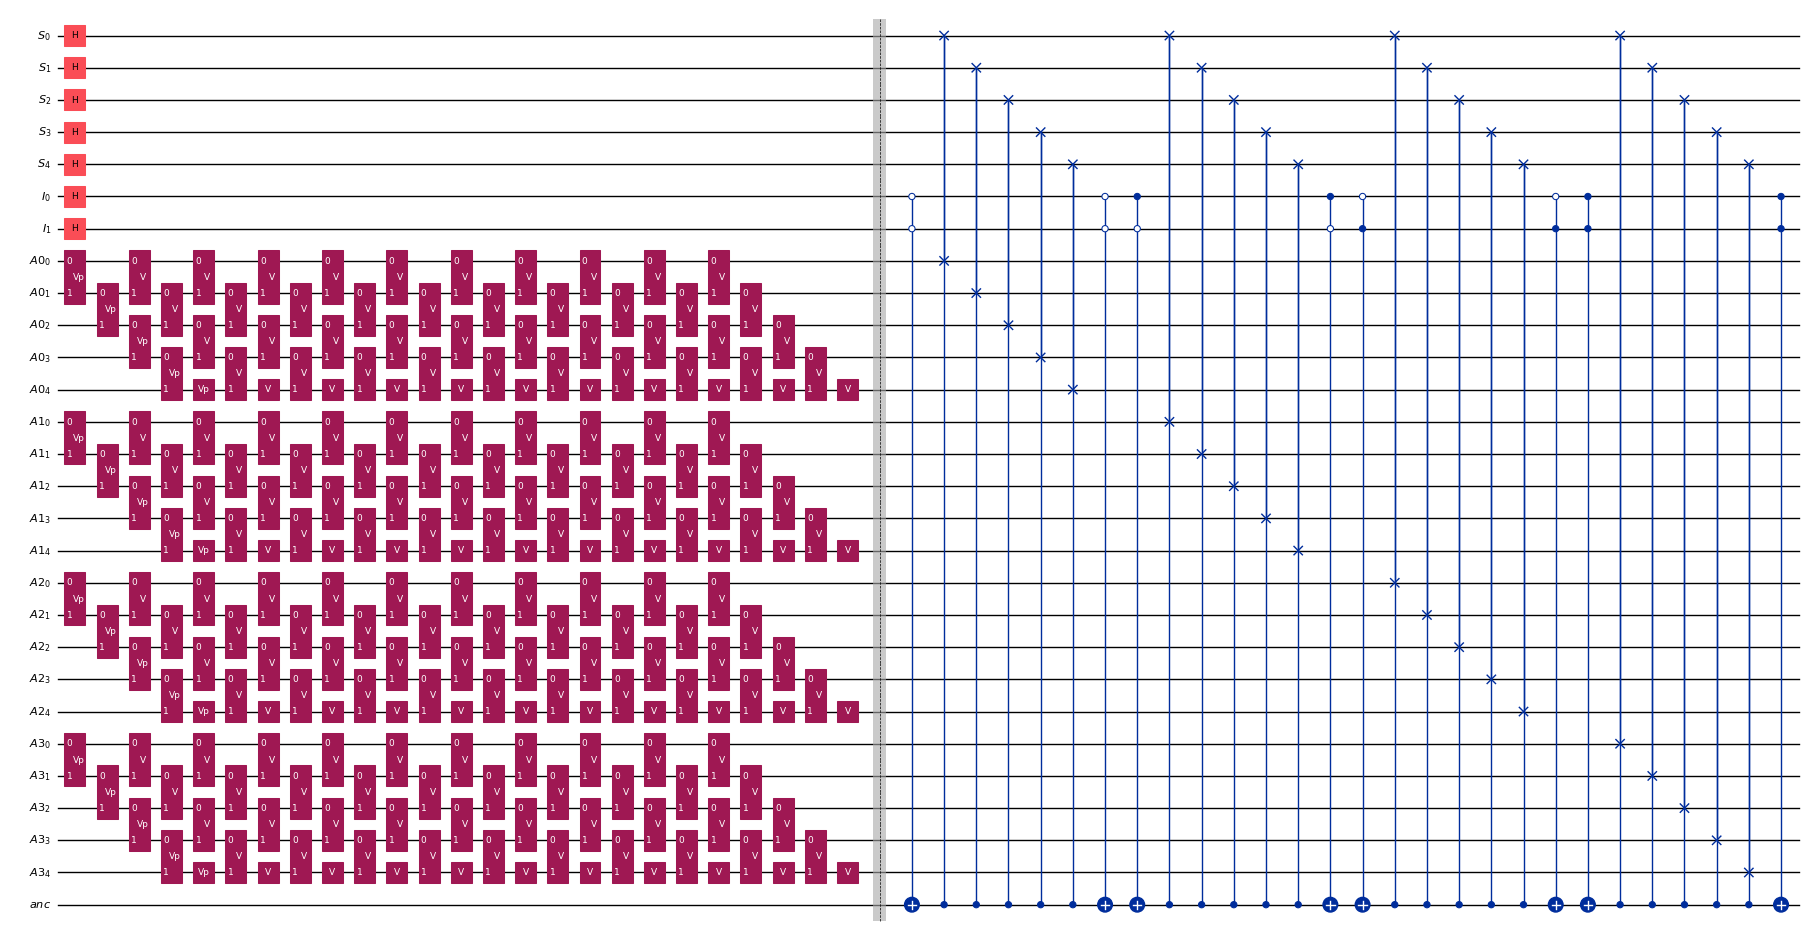

In [ ]:
#DO NOT RUN AS WILL OVERWRITE CIRCUIT
#qc, layout = mre.build_compression_circuit(chunks, prep_circuits=prep_circuits,
                                           decomposed=True, barrier=True)
print(f"qubits = {qc.num_qubits}  (S={layout['n']}, I={layout['m']}, "
      f"{M}xA={M*layout['n']}, anc=1)")
print(f"depth  = {qc.depth()}   gates = {qc.size()}")
show(qc, fold=-1, scale=0.5)

### TKET decomposition

In [7]:
from pytket.extensions.quantinuum import QuantinuumBackend
from pytket.extensions.qiskit import qiskit_to_tk

tk_circ = qiskit_to_tk(qc)

backend = QuantinuumBackend("H2-1")

compiled = backend.get_compiled_circuit(
    tk_circ,
    optimisation_level=2
)
from pytket.extensions.qiskit import tk_to_qiskit

qiskit_compiled = tk_to_qiskit(compiled)

print(compiled)

<tket::Circuit, qubits=28, gates=2041>


In [8]:
from collections import Counter

gate_counts = Counter(cmd.op.type.name for cmd in compiled)
print(gate_counts)

Counter({'PhasedX': 1316, 'ZZPhase': 676, 'Rz': 48, 'Barrier': 1})


## 4. Full statevector simulation + inner-product smoke test

Simulate all 28 qubits; for a measurement outcome `u`, project the prep registers onto
`|u>` (ancilla onto `|0>`) and take the inner product of the storage+index block with the
analytic weighted stack `weighted_stack_vector(chunks, u)`.

Because the compression is exact, the only infidelity is the SSO prep error, so the
reconstruction fidelity should equal $\prod_i F_i$ (Eq. 5). Outcomes are drawn with the
Appendix B sampler plus the deterministic peak outcome.

In [9]:
sv = mre.simulate_statevector(qc)
print(f"statevector: {sv.nbytes/1e9:.2f} GB   ancilla leak (|1> norm) = "
      f"{mre.ancilla_leak(sv, layout):.2e}   (should be ~0)")

test_us = [mre.peak_outcome(chunks)] + mre.sample_outcomes(chunks, n_samples=5, seed=7)
print("\noutcome u                         P_sim        |<sim|psi_w>|^2")
fids_by_u = []
for u in test_us:
    block, nrm = mre.extract_SI(sv, u, layout)
    f = mre.fidelity(block, mre.weighted_stack_vector(chunks, u))
    fids_by_u.append(f)
    print(f"{str(u):32s} {nrm**2:.3e}   {f:.12f}")
typical, worst = fids_by_u[0], min(fids_by_u)
print(f"\ntypical (peak outcome) fidelity = {typical:.12f}   (infid {1-typical:.2e})")
print(f"worst  (tail outcome)  fidelity = {worst:.12f}   (infid {1-worst:.2e})")
print(f"prod_i F_i (SSO floor)          = {prodF:.12f}   (infid {1-prodF:.2e})")
assert worst > 1 - 1e-6, "reconstruction well below the 10-layer SSO precision"
print("\nSMOKE TEST PASSED -- compression is exact, so reconstruction infidelity is the")
print("SSO prep error only: high-probability outcomes reach prod_i F_i (~1e-9); low-")
print("probability tail outcomes (tiny amplitudes) sit at the 10-layer SSO floor (~1e-8).")

statevector: 4.29 GB   ancilla leak (|1> norm) = 0.00e+00   (should be ~0)

outcome u                         P_sim        |<sim|psi_w>|^2
(10, 11, 5, 12)                  3.798e-03   0.999999999478
(15, 14, 5, 20)                  6.248e-05   0.999999999921
(9, 14, 5, 12)                   3.960e-04   0.999999999694
(25, 11, 5, 12)                  5.726e-04   0.999999999681
(10, 11, 8, 12)                  3.205e-03   0.999999999442
(13, 11, 31, 14)                 5.236e-08   0.999999770346

typical (peak outcome) fidelity = 0.999999999478   (infid 5.22e-10)
worst  (tail outcome)  fidelity = 0.999999770346   (infid 2.30e-07)
prod_i F_i (SSO floor)          = 0.999999998650   (infid 1.35e-09)

SMOKE TEST PASSED -- compression is exact, so reconstruction infidelity is the
SSO prep error only: high-probability outcomes reach prod_i F_i (~1e-9); low-
probability tail outcomes (tiny amplitudes) sit at the 10-layer SSO floor (~1e-8).


## 5. Cross-check: Fig. 2 decomposition vs. undecomposed controlled-swaps

Rebuild with `decomposed=False` (m-controlled `SwapGate`s, no ancilla) and confirm the
storage+index state is identical -- i.e. the ancilla decomposition is faithful.

In [10]:
qc_logical, layout_l = mre.build_compression_circuit(chunks, prep_circuits=prep_circuits,
                                                    decomposed=False)
sv_l = mre.simulate_statevector(qc_logical)
u = mre.peak_outcome(chunks)
b_d, _ = mre.extract_SI(sv,   u, layout)
b_l, _ = mre.extract_SI(sv_l, u, layout_l)
print(f"decomposed vs logical fidelity = {mre.fidelity(b_d, b_l):.12f}")
assert mre.fidelity(b_d, b_l) > 1 - 1e-8
print("decomposition is faithful")

decomposed vs logical fidelity = 1.000000000000
decomposition is faithful


## 6. Baseline comparison: direct chi=2 encoding (no multi-register)

For comparison, encode the SAME data directly as one flattened `4*32 = 128`-dimensional
state (`n = 7` qubits) with the identical chi=2 SSO staircase method used per-row above --
no chunking, no compression circuit. This is the paper's "full state vector" baseline
(Fig. 4/6): row-by-row + compression works with an easier (lower-entanglement) chunk per
register, versus one harder disentangling problem on the whole state.

The target vector uses the same concatenation order as the chunks above (`Y.T.flatten()`
= row0 ++ row1 ++ row2 ++ row3), so this is apples-to-apples against the Section 3 circuit.

Note that there was an issues with this specific case as due to high convergence we lost schmidt coefficients past chi2.

*Note: at this small 4-row scale, direct chi=2 still converges reasonably well given enough
layers -- the dramatic fidelity plateau the paper shows for direct encoding is most
pronounced at larger row counts (see the paper's M=128 vs M=8 comparison, Fig. 6). The
comparison here is mainly qubit/gate-count/depth trade-offs at a fixed, fully-verifiable
scale.*

In [ ]:
DIRECT_K_CHI2 = 50      # matches the analysis notebook's ULTRA_K_CHI2 convention
DIRECT_N_ITER = 200

v_direct = Y.T.flatten().astype(complex)
v_direct = v_direct / np.linalg.norm(v_direct)
n_direct = int(np.log2(len(v_direct)))
print(f"direct target: n={n_direct} qubits, dim={len(v_direct)}  (== {M}*{N})")

#DO NOT RUN AS WILL OVERWRITE CIRCUIOT
#qc_direct = srp.build_row_circuit(v_direct, chi=2, num_layers=DIRECT_K_CHI2, n_iter=DIRECT_N_ITER)
print(f"\nchi=2, {DIRECT_K_CHI2} layers:")
print(f"  qubits = {qc_direct.num_qubits}   depth = {qc_direct.depth()}   gates = {qc_direct.size()}")
print(f"  sso_fid (vs target)     = {qc_direct.metadata['sso_fid']:.10f}  "
      f"(infid {1-qc_direct.metadata['sso_fid']:.2e})")
print(f"  assembly_fid (vs recon) = {qc_direct.metadata['assembly_fid']:.10f}  "
      f"(circuit correctly implements the fit, independent of fit quality)")

direct target: n=7 qubits, dim=128  (== 4*32)



chi=2, 50 layers:
  qubits = 7   depth = 107   gates = 357
  sso_fid (vs target)     = 0.9999999909  (infid 9.07e-09)
  assembly_fid (vs recon) = 1.0000000000  (circuit correctly implements the fit, independent of fit quality)


### 6a. Convergence: infidelity vs. staircase layer

Same style as the paper's Fig. 4/6. Compare against `prod_i F_i` from Section 2 -- that's
the multi-register floor at 10 layers/row (5 qubits each); here all `DIRECT_K_CHI2` layers
act on the full 7-qubit state at once.

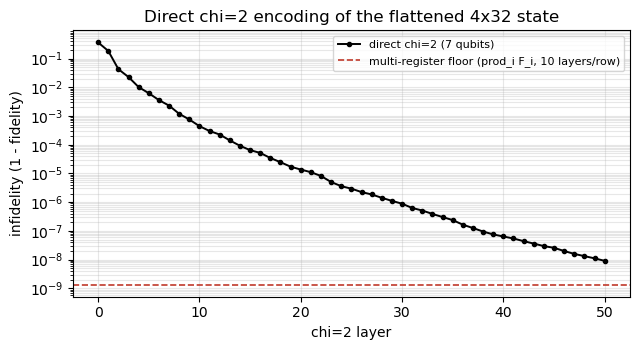

In [12]:
chi_fids_direct = qc_direct.metadata['chi_fids']
infid_direct = np.clip(1.0 - np.array(chi_fids_direct), 1e-16, None)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(range(len(infid_direct)), infid_direct, marker='o', ms=3, lw=1.4, color='black',
           label='direct chi=2 (7 qubits)')
ax.axhline(1 - prodF, color='#c0392b', ls='--', lw=1.2,
          label=f'multi-register floor (prod_i F_i, 10 layers/row)')
ax.set_xlabel('chi=2 layer'); ax.set_ylabel('infidelity (1 - fidelity)')
ax.set_title('Direct chi=2 encoding of the flattened 4x32 state')
ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6b. The direct-encoding circuit

Same structure as a single row prep (Section 2a) -- analytic residual prep (`Vp`) then the
reversed staircase layers (`V`) -- just `DIRECT_K_CHI2` layers deep on all 7 qubits instead
of 10 layers on 5.

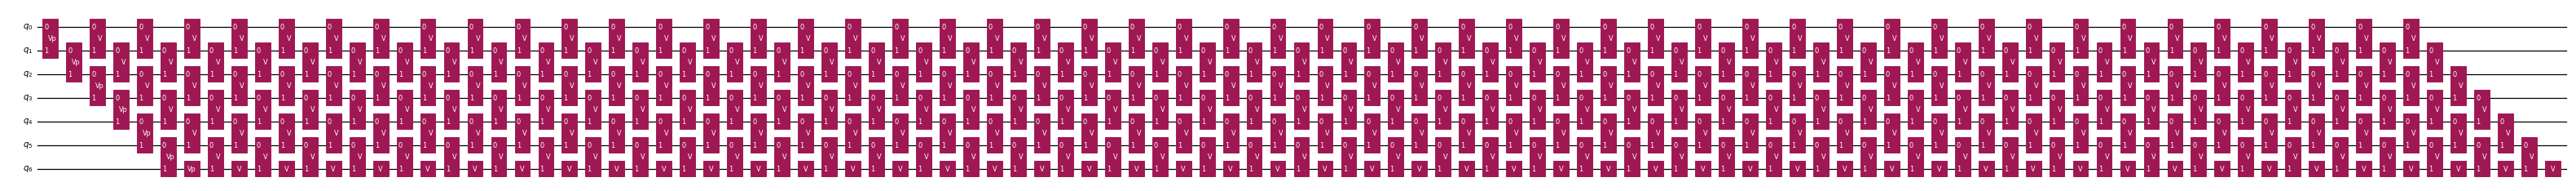

In [13]:
show(qc_direct, fold=-1, scale=0.45)

In [14]:
from pytket.extensions.quantinuum import QuantinuumBackend
from pytket.extensions.qiskit import qiskit_to_tk

tk_circ_direct = qiskit_to_tk(qc_direct)

backend = QuantinuumBackend("H2-1")

compiled_direct = backend.get_compiled_circuit(
    tk_circ_direct,
    optimisation_level=2
)
from pytket.extensions.qiskit import tk_to_qiskit

qiskit_compiled_direct = tk_to_qiskit(compiled_direct)

print(compiled_direct)

<tket::Circuit, qubits=7, gates=2768>


In [15]:
from collections import Counter

gate_counts = Counter(cmd.op.type.name for cmd in compiled_direct)
print(gate_counts)

Counter({'PhasedX': 1843, 'ZZPhase': 918, 'Rz': 7})


## 7. Notes

* **Exact-prep oracle.** `mre.build_compression_circuit(chunks)` with the default
  `row_prep_exact` (Qiskit `StatePreparation`) gives reconstruction fidelity **1.0** to
  machine precision -- use it to confirm the compression machinery independent of prep
  quality. Swapping in the SSO circuits (this notebook) is what makes the reconstruction
  fidelity drop to $\prod_i F_i$.
* **Hardware.** `sso_rowprep.build_row_circuit` emits 2-qubit `unitary` gates; hand `qc`
  to `pytket` (`qiskit_to_tk`) and compile with `QuantinuumBackend` to rebase to the
  H-series native gate set (PhasedX, Rz, ZZPhase) over all-to-all connectivity.
* **Convention.** The SSO circuit uses site i -> qubit (n-1-i); its statevector equals the
  row in the same little-endian convention as `StatePreparation`, so exact and SSO prep are
  interchangeable without touching the oracle.

## 8. Save circuits for the shadow-overlap notebook

Serialises `qc`, `qc_direct`, and `prep_circuits` via **QPY** (Qiskit's native binary
circuit format) so the new shadow-overlap notebook loads the exact same objects rather
than re-fitting them. Verified by round-trip test (below) to preserve the exact unitaries,
gate labels (`Vp`/`V`), and the `.metadata` dict (fidelities, `chi_fids`) losslessly.
QASM was not used: these circuits are built almost entirely from `qc.unitary(...)`
(arbitrary matrices), which QASM can't represent exactly.

The classical target vectors (`chunks`, `v_direct`) are saved alongside as a `.npz`, since
shadow-overlap fidelity estimation needs both the circuit and its known classical target.

In [16]:
from qiskit import qpy

with open('mre_qc.qpy', 'wb') as f:
    qpy.dump([qc], f)
with open('mre_qc_direct.qpy', 'wb') as f:
    qpy.dump([qc_direct], f)
with open('mre_prep_circuits.qpy', 'wb') as f:
    qpy.dump(prep_circuits, f)

np.savez('mre_target_data.npz', chunks=np.stack(chunks), v_direct=v_direct, Y=Y, M=M, N=N)
print("saved: mre_qc.qpy, mre_qc_direct.qpy, mre_prep_circuits.qpy, mre_target_data.npz")

saved: mre_qc.qpy, mre_qc_direct.qpy, mre_prep_circuits.qpy, mre_target_data.npz


In [17]:
# round-trip check (only meaningful here, where qc/qc_direct are already in memory)
with open('mre_qc.qpy', 'rb') as f:
    qc_check = qpy.load(f)[0]
with open('mre_qc_direct.qpy', 'rb') as f:
    qc_direct_check = qpy.load(f)[0]

sv_a = mre.simulate_statevector(qc);        sv_b = mre.simulate_statevector(qc_check)
print(f"qc round-trip fidelity        = {mre.fidelity(sv_a, sv_b):.12f}")
sv_a = mre.simulate_statevector(qc_direct); sv_b = mre.simulate_statevector(qc_direct_check)
print(f"qc_direct round-trip fidelity = {mre.fidelity(sv_a, sv_b):.12f}")
print(f"qc_direct.metadata preserved  = {qc_direct_check.metadata == qc_direct.metadata}")

qc round-trip fidelity        = 1.000000000000


qc_direct round-trip fidelity = 1.000000000000
qc_direct.metadata preserved  = True


### Load cell -- paste this into the new shadow-overlap notebook

Keep `mre_qc.qpy`, `mre_qc_direct.qpy`, `mre_prep_circuits.qpy`, and `mre_target_data.npz`
in the new notebook's working directory (e.g. the same `MultiRegister Encoding/` folder).

```python
import numpy as np
from qiskit import qpy

with open('mre_qc.qpy', 'rb') as f:
    qc = qpy.load(f)[0]
with open('mre_qc_direct.qpy', 'rb') as f:
    qc_direct = qpy.load(f)[0]
with open('mre_prep_circuits.qpy', 'rb') as f:
    prep_circuits = qpy.load(f)

data = np.load('mre_target_data.npz')
chunks = list(data['chunks'])       # 4 row vectors, chunks[i].shape == (32,)
v_direct = data['v_direct']         # flattened 128-dim direct-encoding target
Y = data['Y']; M = int(data['M']); N = int(data['N'])

print(f"qc: {qc.num_qubits}q   qc_direct: {qc_direct.num_qubits}q   "
      f"{len(prep_circuits)} prep circuits   chunks: {len(chunks)}x{chunks[0].shape}")
```

# Shadow overlap work

In [18]:
import numpy as np
from scipy.stats import norm, t
import matplotlib.pyplot as plt


def rotated_outcome_to_zket(measurement_outcome, pauli):
    """
    Map a measurement outcome in a Pauli basis back to the Z basis for the
    classical shadows omega calculation.
    """
    if pauli == 'Z':
        s_ket = np.array([1,0], dtype=complex) if measurement_outcome == 0 else np.array([0,1], dtype=complex)
    elif pauli == 'X':
        s_ket = np.array([1, 1], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    elif pauli == 'Y':
        s_ket = np.array([1, 1j], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    else:
        raise ValueError("Pauli must be 'X', 'Y', or 'Z'")
    return s_ket


def split_bitstring(bitstring, target_qubit):
    """
    Given a bitstring and a target qubit index, return two bitstrings:
    - one with target qubit = 0
    - one with target qubit = 1
    """
    if target_qubit < 0 or target_qubit >= len(bitstring):
        raise ValueError("Target qubit index out of range")
    bits = list(bitstring)
    bits0 = bits.copy()
    bits1 = bits.copy()
    bits0[target_qubit] = '0'
    bits1[target_qubit] = '1'
    return ''.join(bits0), ''.join(bits1)


def build_conditional_postmeasurement_single_qubit(target_state, measurement, target_qubit, verbose: bool = False):
    """Takes a target state from which a conditional post measurement state is built,
    a single qubit state of the target qubit specific to the measurement given."""
    zero_component, one_component = split_bitstring(measurement, target_qubit)

    conditional_single_qubit_state = np.array([
        target_state[int(zero_component, 2)],
        target_state[int(one_component, 2)]
    ], dtype=complex)

    norm_ = np.linalg.norm(conditional_single_qubit_state)

    if norm_ == 0:
        if verbose:
            print("Conditional single target state does not exist so returning zero vector so that w=0 as paper says to do!")
        return np.array([0,0], dtype=complex)
    return conditional_single_qubit_state / norm_


def compute_local_overlap(conditional_target_qubit_state, measurement_outcome, P, verbose: bool=False):
    """
    Computes the omega overlap for a single-qubit conditional state.
    """
    conditional_target_qubit_state = np.array(conditional_target_qubit_state, dtype=complex)

    s_ket = rotated_outcome_to_zket(measurement_outcome, P)
    projector = np.outer(s_ket, s_ket.conj())  # |s><s|
    O3 = 3*projector - np.eye(2, dtype=complex)

    if verbose:
        print("Measurement outcome was: ", measurement_outcome)
        print("3|s><s| - I is: ", O3)

    omega = np.vdot(conditional_target_qubit_state, O3 @ conditional_target_qubit_state).real
    return omega


def get_snapshot(circuit, num_qubits, verbose: bool=False, basis_select=False):
    '''This will take a circuit and randomly pick a qubit as the target, take a measurement in the pauli basis'''
    circ = circuit.copy()

    target_qubit = np.random.randint(0, num_qubits)
    if basis_select:
        target_qubit = basis_select[0]
    if verbose:
        print("Target Qubit is: ", target_qubit)

    paulis = ['X', 'Y', 'Z']
    unitary_id = np.random.randint(0, 3)
    if basis_select:
        unitary_id = basis_select[1]

    P = paulis[unitary_id]
    if verbose:
        print("Measuring ", P, " at target qubit")
    if P == 'X':
        circ.apply_gate('H', target_qubit)            # H maps X->Z
    elif P == 'Y':
        circ.apply_gate('Sdg', target_qubit)          # Sdg then H maps Y->Z
        circ.apply_gate('H', target_qubit)
    # P == 'Z' -> do nothing
    if verbose:
        print("Measuring qubits from state:")
        print(circ.psi.to_dense())
        circ.draw()

    state = circ.psi.to_dense()
    state = state / np.linalg.norm(state)
    probs = np.abs(state)**2

    idx = np.random.choice(len(probs.flatten()), p=probs.flatten())
    bitstring = np.binary_repr(idx, width=num_qubits)
    if verbose:
        print("Result: ", bitstring)
    return bitstring, target_qubit, P

def get_snapshot_qiskit(circuit, num_qubits, verbose=False, basis_select=False):
    #replacement function for running qiskit circuit rather than quimb
    circ = circuit.copy()

    target_qubit = np.random.randint(0, num_qubits) if not basis_select else basis_select[0]
    paulis = ['X', 'Y', 'Z']
    P = paulis[np.random.randint(0, 3)] if not basis_select else paulis[basis_select[1]]

    if P == 'X':
        circ.h(target_qubit)
    elif P == 'Y':
        circ.sdg(target_qubit); circ.h(target_qubit)

    state = mre.simulate_statevector(circ)          # or Statevector(circ) for small circuits
    probs = np.abs(state) ** 2
    idx = np.random.choice(len(probs), p=probs)
    bitstring = np.binary_repr(idx, width=num_qubits)

    # target_qubit (Qiskit index) -> string position, so callers keep indexing bits[target_qubit] unchanged
    string_pos = num_qubits - 1 - target_qubit
    return bitstring, string_pos, P


def run_multiple_shadow_overlaps(target_state, circuit, num_qubits, num_snapshots, verbose: bool=False, basis_select=False):
    '''runs shadow overlaps on qubits.
    basis_select is for choosing a specific basis to test (qubit_num,pauli). qubit num starts from 0 and pauli is 0=X,1=Y,2=Z'''
    estimated_fideleities = []
    for i in range(num_snapshots):
        if verbose:
            print("Getting snapshot...")
        measurement, target_qubit, Pauli = get_snapshot(circuit, num_qubits, verbose=verbose, basis_select=basis_select)

        if verbose:
            print("Building conditional target qubit state...")
        conditional_target_qubit_state = build_conditional_postmeasurement_single_qubit(target_state, measurement, target_qubit, verbose=verbose)

        if verbose:
            print("Getting Single Estimate")
        single_estimate = compute_local_overlap(conditional_target_qubit_state, int(measurement[target_qubit]), Pauli, verbose=verbose)
        estimated_fideleities.append(single_estimate)
    return estimated_fideleities


def get_confidence_interval(samples, confidence=0.95, verbose: bool=False):
    """
    Compute a confidence interval for a set of shadow measurement samples.
    """
    samples = np.array(samples)
    n = len(samples)
    mean = np.mean(samples)
    var = np.var(samples, ddof=1)
    std_err = np.sqrt(var / n)

    z = norm.ppf(0.5 + confidence / 2)
    lower = mean - z * std_err
    upper = mean + z * std_err

    if verbose:
        print(f"Number of samples: {n}")
        print(f"Mean: {mean}")
        print(f"Standard error: {std_err}")
        print(f"{int(confidence*100)}% confidence interval: [{lower}, {upper}]")

    return (lower, upper)


def plot_single_shot_CI(values, tau, bins=20, title="Shot", show_mean=True, ci=0.90, show_fidelity: bool=True):
    """
    Plot a single-shot distribution with optional mean line and a shaded
    confidence interval for the population mean.
    """
    values = np.array(values)
    n = len(values)
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)

    alpha = 1 - ci
    t_multiplier = t.ppf(1 - alpha/2, df=n-1)
    sem = std_val / np.sqrt(n)
    ci_lower = mean_val - t_multiplier * sem
    ci_upper = mean_val + t_multiplier * sem

    plt.figure(figsize=(6, 4))
    plt.hist(values, bins=bins, alpha=0.6, color='black', edgecolor='black')

    if show_mean:
        plt.axvline(mean_val, color='black', linestyle='--', label=f'Mean = {mean_val:.3f}')

    plt.axvspan(ci_lower, ci_upper, color='red', alpha=0.2, label=f'{int(ci*100)}% CI = [{ci_lower:.3f}, {ci_upper:.3f}]')
    if show_fidelity:
        plt.axvspan(1-tau*(1-ci_lower), 1, color='orange', alpha=0.2, label=f'Fidelity range = [{1-tau*(1-ci_lower):.3f}, {1:.3f}]')

    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
